# W2/Bures trajectories for scalar Gaussian two-layer linear networks

This notebook explores the Gaussian second-moment reduction of the two-layer linear network flow in the smallest nontrivial case: scalar incoming and outgoing weights. A centered Gaussian neuron law on `(u, v)` is described by

\[
\Sigma = \begin{pmatrix} p & r \\ r & q \end{pmatrix},
\]

where `r` is the learned predictor and `p,q` are the hidden variances. For the whitened least-squares loss

\[
F(\Sigma)=\frac12(r-\beta)^2,
\]

the W2 gradient flow of the Gaussian law is the Bures flow on `Sigma`:

\[
\dot p = -2r(r-\beta), \qquad
\dot q = -2r(r-\beta), \qquad
\dot r = -(p+q)(r-\beta).
\]

The invariants are

\[
p-q, \qquad pq-r^2.
\]

This is the scalar version of the covariance-level conservation law for `J Sigma`, with `J=diag(1,-1)`. The figure generated below has two panels:

- equal variances `p=q`, where the flow lives in the 2D cone `s >= |r|`;
- unequal variances, where the same geometry becomes the 3D Lorentz cone.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

plt.rcParams.update({
    "font.size": 6,
    "font.family": "serif",
    "axes.titlesize": 8,
    "axes.labelsize": 6,
    "legend.fontsize": 6,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "pgf.preamble": "\n".join([
        r"\usepackage{amsfonts}",  # Fixes the \mathbb error
        r"\usepackage{amssymb}",   # Optional: adds extra math symbols
    ])
})

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "code" / "figures").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the repository")

FIG_DIR = ROOT / "code" / "figures"
RESULTS_DIR = ROOT / "code" / "notebooks" / "research" / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

beta = 1.0
colors = ["#2458A6", "#D1495B", "#00876C", "#7A3E9D", "#E08D2D", "#2B8CBE"]

## Invariant coordinates

It is useful to switch from `(p,q,r)` to Lorentz coordinates

\[
a = \frac{p+q}{2}, \qquad b = \frac{p-q}{2}.
\]

Then positive semidefiniteness becomes

\[
a^2 \ge r^2+b^2, \qquad a\ge 0,
\]

which is a second-order cone. The flow is

\[
\dot a = -2r(r-\beta), \qquad
\dot b = 0, \qquad
\dot r = -2a(r-\beta).
\]

Thus `b` is conserved, and so is

\[
\alpha^2 = a^2-r^2-b^2 = pq-r^2.
\]

For fixed `b` and `alpha`, define

\[
h = \sqrt{b^2+\alpha^2}, \qquad r=h\sinh\theta, \qquad a=h\cosh\theta.
\]

The trajectory is reduced to the scalar ODE

\[
\dot\theta = 2(\beta-h\sinh\theta),
\]

and converges to the selected global minimizer

\[
r_\infty=\beta, \qquad
a_\infty=\sqrt{\beta^2+b^2+\alpha^2}.
\]

In [2]:
def rk4_theta(theta0, h, beta=1.0, t_final=4.0, n_steps=500):
    """Integrate theta' = 2(beta - h sinh(theta)) with a fixed-step RK4 scheme."""
    t = np.linspace(0.0, t_final, n_steps)
    theta = np.empty_like(t)
    theta[0] = theta0
    dt = t[1] - t[0]

    def f(th):
        return 2.0 * (beta - h * np.sinh(th))

    for k in range(n_steps - 1):
        th = theta[k]
        k1 = f(th)
        k2 = f(th + 0.5 * dt * k1)
        k3 = f(th + 0.5 * dt * k2)
        k4 = f(th + dt * k3)
        theta[k + 1] = th + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, theta


def trajectory(alpha, b, r0, beta=1.0, t_final=4.0, n_steps=500):
    """Return a W2/Bures trajectory with invariants b and alpha^2."""
    h = np.sqrt(alpha**2 + b**2)
    if h <= 0:
        raise ValueError("Use alpha^2+b^2 > 0 to avoid the cone vertex.")
    theta0 = np.arcsinh(r0 / h)
    t, theta = rk4_theta(theta0, h, beta=beta, t_final=t_final, n_steps=n_steps)
    r = h * np.sinh(theta)
    a = h * np.cosh(theta)
    b_arr = np.full_like(r, b)
    p = a + b_arr
    q = a - b_arr
    return {"t": t, "r": r, "a": a, "b": b_arr, "p": p, "q": q, "alpha": alpha, "h": h}


def add_curve_arrow(ax, x, y, color, frac=0.55):
    idx = int(frac * (len(x) - 2))
    ax.annotate(
        "",
        xy=(x[idx + 1], y[idx + 1]),
        xytext=(x[idx], y[idx]),
        arrowprops=dict(arrowstyle="-|>", color=color, lw=1.25, shrinkA=0, shrinkB=0),
    )

## Figure generation

The left panel is the equal-variance slice `b=0`, so `a=s=(p+q)/2=p=q` and the feasible set is the simple cone `s>=|r|`. The gray hyperbolas are invariant leaves `s^2-r^2=alpha^2`; the vertical green line is the global minimizer set `r=beta`.

The right panel removes the equal-variance assumption. The feasible region is the 3D Lorentz cone `a^2>=r^2+b^2`, where `b=(p-q)/2` measures layer-variance imbalance. The W2/Bures trajectories stay on a fixed `b` plane and a fixed determinant leaf `a^2-r^2-b^2=alpha^2`, then hit the minimizer sheet `r=beta`.

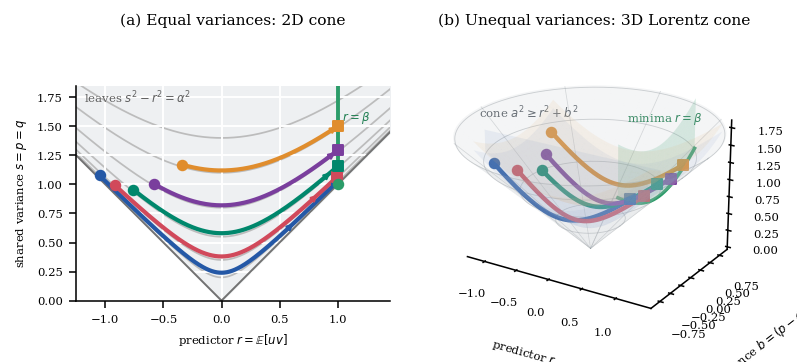

wrote /home/syz/Projects/linear-networks-global/python/figures/gaussian_w2_cone_geometry.pdf
wrote /home/syz/Projects/linear-networks-global/python/figures/gaussian_w2_cone_geometry.pgf
wrote /home/syz/Projects/linear-networks-global/python/figures/gaussian_w2_cone_geometry.png


In [69]:
fig = plt.figure(figsize=(2.15, 3.35))
grid = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.08], left=0.25, right=0.95, bottom=0.12, top=0.96, hspace=0.34)
ax2 = fig.add_subplot(grid[0, 0])
ax3 = fig.add_subplot(grid[1, 0], projection="3d")

# -----------------------------------------------------------------------------
# Panel A: equal variances, b=0.
# -----------------------------------------------------------------------------
r_min, r_max = -1.25, 1.45
a_max = 1.85
r_grid = np.linspace(r_min, r_max, 700)

ax2.fill_between(r_grid, np.abs(r_grid), a_max, color="#EEF0F2", alpha=1.0, zorder=0)
ax2.plot(r_grid, np.abs(r_grid), color="#727272", lw=1.0, label=r"cone boundary $s=|r|$")

for alpha in [0.20, 0.35, 0.55, 0.80, 1.10, 1.40]:
    ax2.plot(
        r_grid,
        np.sqrt(r_grid**2 + alpha**2),
        color="#B7B7B7",
        lw=0.9,
        alpha=0.9,
        zorder=1,
    )

ax2.plot([beta, beta], [abs(beta), a_max], color="#2B9C69", lw=2.0, label=r"global minima $r=\beta$")
ax2.scatter([beta], [abs(beta)], s=24, color="#2B9C69", zorder=5)

same_variance_specs = [
    (0.24, -1.05, colors[0]),
    (0.38, -0.92, colors[1]),
    (0.58, -0.76, colors[2]),
    (0.82, -0.58, colors[3]),
    (1.12, -0.34, colors[4]),
]
for alpha, r0, color in same_variance_specs:
    tr = trajectory(alpha=alpha, b=0.0, r0=r0, beta=beta, t_final=4.2)
    ax2.plot(tr["r"], tr["a"], color=color, lw=2.15, zorder=3)
    ax2.scatter(tr["r"][0], tr["a"][0], color=color, s=24, marker="o", zorder=4)
    ax2.scatter(tr["r"][-1], tr["a"][-1], color=color, s=28, marker="s", zorder=4)
    add_curve_arrow(ax2, tr["r"], tr["a"], color, frac=0.48)

ax2.text(-1.18, 1.70, r"leaves $s^2-r^2=\alpha^2$", color="#5F5F5F")
ax2.text(beta + 0.035, 1.55, r"$r=\beta$", color="#207F52")
ax2.set_xlim(r_min, r_max)
ax2.set_ylim(0.0, a_max)
ax2.set_xlabel(r"predictor $r$")
ax2.set_ylabel(r"shared variance $s$")
panel_a_title = "(a) Equal variances"
ax2.set_title(panel_a_title, pad=2)
ax2.set_aspect("auto")
ax2.set_anchor("C")
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(color="#FFFFFF", lw=1.0)

# -----------------------------------------------------------------------------
# Panel B: unequal variances, full Lorentz cone.
# -----------------------------------------------------------------------------
rho = np.linspace(0.0, 1.72, 58)
phi = np.linspace(0.0, 2 * np.pi, 96)
RHO, PHI = np.meshgrid(rho, phi)
X_cone = RHO * np.cos(PHI)
Y_cone = RHO * np.sin(PHI)
Z_cone = RHO
ax3.plot_surface(X_cone, Y_cone, Z_cone, color="#BFC5CA", alpha=0.16, linewidth=0, shade=False)

# A few circular rims make the cone readable in PDF.
for rr in [0.45, 0.90, 1.35, 1.70]:
    ph = np.linspace(0, 2 * np.pi, 240)
    ax3.plot(rr * np.cos(ph), rr * np.sin(ph), rr * np.ones_like(ph), color="#8F969C", lw=0.45, alpha=0.45)
for ph0 in np.linspace(0, 2 * np.pi, 8, endpoint=False):
    rr = np.linspace(0, 1.72, 80)
    ax3.plot(rr * np.cos(ph0), rr * np.sin(ph0), rr, color="#8F969C", lw=0.4, alpha=0.35)

# Translucent determinant leaves alpha^2 = a^2-r^2-b^2.
RR, BB = np.meshgrid(np.linspace(-1.18, 1.42, 60), np.linspace(-0.88, 0.88, 54))
for alpha, color, opacity in [(0.35, "#8EA7D8", 0.13), (0.72, "#E8B26C", 0.12)]:
    AA = np.sqrt(RR**2 + BB**2 + alpha**2)
    ax3.plot_surface(RR, BB, AA, color=color, alpha=opacity, linewidth=0, shade=False)

# Global minimizer sheet r=beta within the cone.
B_sheet, U_sheet = np.meshgrid(np.linspace(-0.92, 0.92, 30), np.linspace(0.0, 0.72, 14))
R_sheet = beta * np.ones_like(B_sheet)
A_sheet = np.sqrt(beta**2 + B_sheet**2) + U_sheet
ax3.plot_surface(R_sheet, B_sheet, A_sheet, color="#2B9C69", alpha=0.18, linewidth=0, shade=False)
ax3.plot(beta * np.ones(200), np.linspace(-0.92, 0.92, 200), np.sqrt(beta**2 + np.linspace(-0.92, 0.92, 200)**2), color="#2B9C69", lw=1.8)

unequal_specs = [
    (0.30, -0.64, -1.05, colors[0]),
    (0.46, -0.32, -0.92, colors[1]),
    (0.64, 0.00, -0.76, colors[2]),
    (0.46, 0.32, -0.92, colors[3]),
    (0.30, 0.64, -1.05, colors[4]),
]
for alpha, b0, r0, color in unequal_specs:
    tr = trajectory(alpha=alpha, b=b0, r0=r0, beta=beta, t_final=4.25)
    ax3.plot(tr["r"], tr["b"], tr["a"], color=color, lw=2.3)
    ax3.scatter(tr["r"][0], tr["b"][0], tr["a"][0], color=color, s=24, marker="o", depthshade=False)
    ax3.scatter(tr["r"][-1], tr["b"][-1], tr["a"][-1], color=color, s=30, marker="s", depthshade=False)

# One invariant plane to make b conservation explicit without clutter.
b0 = unequal_specs[0][1]
R_plane, A_plane = np.meshgrid(np.linspace(-1.18, 1.42, 16), np.linspace(0.15, 1.72, 16))
B_plane = b0 * np.ones_like(R_plane)
mask = A_plane >= np.sqrt(R_plane**2 + B_plane**2)
R_plane = np.where(mask, R_plane, np.nan)
A_plane = np.where(mask, A_plane, np.nan)
B_plane = np.where(mask, B_plane, np.nan)
ax3.plot_surface(R_plane, B_plane, A_plane, color="#2458A6", alpha=0.08, linewidth=0, shade=False)

ax3.text(-1.10, -0.85, 1.98, r"cone $a^2\geq r^2+b^2$", color="#596067")
ax3.text(beta - 0.9, 0.72, 1.63, r"minima $r=\beta$", color="#207F52")
ax3.set_xlim(-1.22, 1.45)
ax3.set_ylim(-0.92, 0.92)
ax3.set_zlim(0.0, 1.82)
ax3.set_xlabel(r"$r$", labelpad=-5)
ax3.set_ylabel(r"$b$", labelpad=-4)
ax3.set_zlabel(r"$a$", labelpad=-7)
ax3.tick_params(axis="both", which="major", labelsize=5, pad=-1)
panel_b_title = "(b) Unequal variances"
ax3.set_title(panel_b_title, pad=0)
ax3.view_init(elev=23, azim=-58)
ax3.set_box_aspect((1.25, 0.90, 0.82), zoom=1.13)
ax3.set_anchor("C")
pos3 = ax3.get_position()
height3 = pos3.height * 1.13
ax3.set_position([pos3.x0 - 0.12, pos3.y1 - height3 - 0.005, pos3.width * 1.13, height3])
ax3.grid(False)
for axis in [ax3.xaxis, ax3.yaxis, ax3.zaxis]:
    axis.pane.set_alpha(0.0)


pdf_path = FIG_DIR / "gaussian_w2_cone_geometry.pdf"
png_path = FIG_DIR / "gaussian_w2_cone_geometry.png"
pgf_path = FIG_DIR / "gaussian_w2_cone_geometry.pgf"
fig.savefig(pdf_path)
fig.savefig(png_path)
fig.savefig(pgf_path)
plt.show()

print(f"wrote {pdf_path}")
print(f"wrote {pgf_path}")
print(f"wrote {png_path}")

## Write a short results draft

The draft below is intentionally lightweight: it records the coordinate choice, the conserved leaves, and what the figure is meant to communicate. It embeds the PNG preview while linking to the vector PDF generated by the notebook.

In [58]:
draft_path = RESULTS_DIR / "gaussian_w2_cone_geometry_draft.md"

md = r"""# Gaussian W2 cone geometry

This draft accompanies `code/notebooks/research/gaussian_w2_cone_geometry.ipynb` and the generated figure
`code/figures/gaussian_w2_cone_geometry.pdf`.

![Gaussian W2/Bures cone geometry](../../../figures/gaussian_w2_cone_geometry.png)

We consider the centered Gaussian law of a scalar two-layer linear neuron `(u,v)`, with
second moment

```math
\Sigma = \begin{pmatrix} p & r \\ r & q \end{pmatrix}.
```

The predictor is the cross moment `r=E[uv]`. For the whitened square loss
`F(Sigma)=1/2 (r-beta)^2`, the Gaussian W2 gradient flow is the Bures flow

```math
\dot p = \dot q = -2r(r-\beta), \qquad
\dot r = -(p+q)(r-\beta).
```

The two scalar invariants are `p-q` and `pq-r^2`. In Lorentz coordinates

```math
a=\frac{p+q}{2}, \qquad b=\frac{p-q}{2},
```

the covariance cone is

```math
a^2 \ge r^2+b^2, \qquad a\ge 0.
```

The equal-variance assumption `p=q` means `b=0`. This is the central two-dimensional
slice of the cone, where the conserved leaves are the hyperbolas

```math
s^2-r^2=\alpha^2, \qquad s=p=q.
```

The global minimizers form the line `r=beta` inside this slice, and each leaf selects
one endpoint `s_infty=sqrt(beta^2+alpha^2)`.

Without the equal-variance assumption, the same picture lives in the full three-dimensional
Lorentz cone. The flow conserves

```math
b=\frac{p-q}{2}, \qquad \alpha^2=a^2-r^2-b^2=pq-r^2,
```

so a trajectory is the intersection of the invariant plane `b=b0` and the invariant
hyperboloid `a^2-r^2-b^2=alpha^2`. The global minimizers are no longer a line in the
full cone; they form the sheet `r=beta`, and each conserved leaf selects the point

```math
r_infty=\beta, \qquad a_infty=\sqrt{\beta^2+b_0^2+\alpha^2}.
```

This is the scalar Gaussian counterpart of the paper's covariance-level conservation law:
the spectrum of `J Sigma` is conserved, while the hyperbolically isotropic equal-variance
leaf upgrades that spectral law into the explicit formula for the hidden covariance.
"""

draft_path.write_text(md)
print(f"wrote {draft_path}")

wrote /home/syz/Projects/linear-networks-global/python/results/gaussian_w2_cone_geometry_draft.md
